# Mazapan - Prototipado en FPGA (interactivo)

Capsula 5. El **mismo RTL** del semaforo, pero en una **FPGA**: hardware
reconfigurable, con bloques **ya fabricados** (LUTs, FFs). Aqui lo sintetizamos
a una FPGA y vemos **cuantos recursos usa** -- y como crece al agregar logica.

> La tarjeta del evento (MinyPLD, MAX V) va por **Quartus**; el flujo open
> source (Yosys) apunta a familias como iCE40, que es lo que usamos aqui para
> el reporte de recursos. La idea es la misma: *configurar bloques listos*.

Corre las celdas en orden.

## 1 - Preparar (instalar Yosys + clonar el repo)

In [1]:
import os, subprocess, re
!apt-get -qq update && apt-get -qq install -y yosys > /dev/null
import matplotlib.pyplot as plt
REPO_URL = 'https://github.com/Misterio12947/galletas-y-postres-chips.git'
REPO = 'galletas-y-postres-chips'
if not os.path.isdir(REPO):
    !git clone --depth 1 $REPO_URL
else:
    !cd $REPO && git pull --ff-only
RTL = f'{REPO}/common/rtl/semaphore/rtl/semaphore.v'
assert os.path.exists(RTL)
print('Yosys y RTL listos.')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Cloning into 'galletas-y-postres-chips'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 70 (delta 2), reused 61 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (70/70), 122.10 KiB | 4.07 MiB/s, done.
Resolving deltas: 100% (2/2), done.
Yosys y RTL listos.


## 2 - ¿Cuantos recursos usa el semaforo en una FPGA?

Yosys **sintetiza** el RTL hacia los bloques de una iCE40 (`synth_ice40`) y nos
dice cuantas **LUTs** (logica) y **FFs** (registros, el estado) ocupa. Fijate:
es el mismo `semaforo`, ahora mapeado a bloques ya fabricados.

In [6]:
def sintetizar(cw=8, mostrar_texto=False):
    cmd = (f'read_verilog {RTL}; chparam -set CW {cw} semaforo; '
           f'synth_ice40 -top semaforo; stat')
    r = subprocess.run(['yosys', '-p', cmd], capture_output=True, text=True)
    out = r.stdout + r.stderr

    # cuenta celdas SB_* del reporte 'stat' (una por linea: "SB_LUT4   18")
    counts = {}
    for ln in out.splitlines():
        m = re.match(r'\s*(SB_\w+)\s+(\d+)\s*$', ln)
        if m:
            counts[m.group(1)] = counts.get(m.group(1), 0) + int(m.group(2))

    luts = counts.get('SB_LUT4', 0)
    ffs  = sum(v for k, v in counts.items() if k.startswith('SB_DFF'))

    if mostrar_texto:
        if counts:
            print('\n'.join(f'{k:14} {v}' for k, v in sorted(counts.items())))
        else:
            print('(no se encontraron celdas SB_*; ultimas lineas de Yosys:)')
            print('\n'.join(out.splitlines()[-15:]))
    return luts, ffs

luts, ffs = sintetizar(cw=8, mostrar_texto=True)
print(f'\n--> LUTs: {luts}   FFs: {ffs}')

SB_CARRY       16
SB_DFFR        20
SB_DFFS        2
SB_LUT4        52

--> LUTs: 52   FFs: 22


## 3 - El reporte, en grafica

Pocas LUTs y FFs: el semaforo es diminuto. Por eso cabe de sobra incluso en una
tarjeta chica. (En la MinyPLD, MAX V, el presupuesto son **80 logic elements**;
aqui el conteo es en bloques iCE40 -- no es 1:1, pero la idea de *presupuesto*
es la misma.)

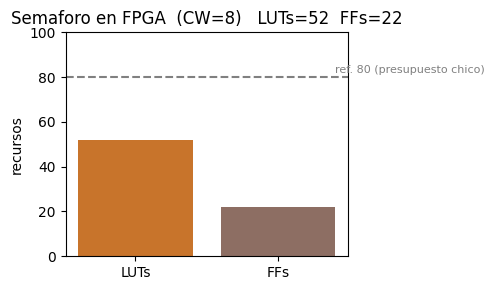

In [7]:
def grafica(cw=8):
    luts, ffs = sintetizar(cw)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(['LUTs', 'FFs'], [luts, ffs], color=['#C8742B', '#8d6e63'])
    ax.axhline(80, ls='--', color='gray')
    ax.text(1.4, 82, 'ref. 80 (presupuesto chico)', fontsize=8, color='gray')
    ax.set_ylim(0, max(90, luts, ffs) + 10)
    ax.set_ylabel('recursos')
    ax.set_title(f'Semaforo en FPGA  (CW={cw})   LUTs={luts}  FFs={ffs}')
    plt.tight_layout(); plt.show()

grafica(8)

## 4 - Juega: mas logica = mas recursos

`CW` es el ancho del contador interno. Subelo y mira como crecen los **FFs**
(cada bit del contador es un registro) y la logica. Asi se siente el
**presupuesto** de una FPGA: todo lo que pongas ocupa bloques.

In [8]:
from ipywidgets import interact, IntSlider
interact(grafica, cw=IntSlider(8, 2, 24, description='CW'));

interactive(children=(IntSlider(value=8, description='CW', max=24, min=2), Output()), _dom_classes=('widget-in…

## 5 - FPGA vs ASIC / lo que sigue

| | FPGA (hoy, en esta demo) | ASIC (el destino final) |
|---|---|---|
| Bloques | ya fabricados (LUTs/FFs) | celdas estandar del PDK |
| "Compila" | minutos | meses |
| Salida | bitstream reprogramable | GDS permanente |

**Mismo RTL, dos destinos.** Ya lo vimos ocupar recursos reales en un tejido
reconfigurable; para la **MinyPLD** eso se hace con Quartus y se baja el
bitstream a la tarjeta (demo en vivo).

Lo siguiente: convertir el mismo RTL en compuertas para el silicio permanente.

🟫 Mazapan &nbsp;->&nbsp; 🍪 Polvorones (Sintesis ASIC)